# Videos of the bars designs: design A, design B and sub-16

Visual design matrices (vdm, 50 × 50 pixels, 1 frame per TR = 2 s) of the two runs of bars (BarsBars, 240 TR):

| panel | design | file |
|---|---|---|
| A | design A (mglRetinotopy, blanks mode): common design of most subjects | `vdm/task-BarsBarsLeftEye_vdm.npy` |
| B | design B (default mode, no blanks): sub-14 and sub-17 (and sub-05 BarsRightEye run-01) | `vdm/sub-14/sub-14_task-BarsBarsLeftEye_vdm.npy` |
| sub-16 LE | sub-16 left eye: run-01 reconstructed, run-02 = design A | `vdm/sub-16/sub-16_task-BarsBarsLeftEye_vdm.npy` |
| sub-16 RE | sub-16 right eye: run-01 and run-02 reconstructed | `vdm/sub-16/sub-16_task-BarsBarsRightEye_vdm.npy` |

The subject folders may be in `vdm/_hold/` while the design-A refit is running: both places are searched. Read only. Videos (mp4, OpenCV as `create_prf_videos.ipynb`) and figures saved in `Desktop/fig_od/design_videos/`.

In [1]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Directories
main_dir = '/Users/uriel/disks/meso_shared'
project_dir = 'amblyo7T_prf'
vdm_dir = '{}/{}/derivatives/vdm'.format(main_dir, project_dir)
out_dir = '/Users/uriel/Desktop/fig_od/design_videos'
os.makedirs(out_dir, exist_ok=True)


def vdm_file(subject, task):
    """Subject vdm, in vdm/sub-XX or vdm/_hold/sub-XX."""
    for d in ['{}/{}'.format(vdm_dir, subject), '{}/_hold/{}'.format(vdm_dir, subject)]:
        fn = '{}/{}_task-{}_vdm.npy'.format(d, subject, task)
        if os.path.isfile(fn):
            return fn
    raise FileNotFoundError('{} {}'.format(subject, task))


designs = {'Design A': '{}/task-BarsBarsLeftEye_vdm.npy'.format(vdm_dir),
           'Design B (sub-14)': vdm_file('sub-14', 'BarsBarsLeftEye'),
           'sub-16 LE': vdm_file('sub-16', 'BarsBarsLeftEye'),
           'sub-16 RE': vdm_file('sub-16', 'BarsBarsRightEye')}
vdm = {name: np.load(fn) for name, fn in designs.items()}
for name, fn in designs.items():
    print('{:20s} {}  {}'.format(name, vdm[name].shape, fn))
n_tr = min(v.shape[2] for v in vdm.values())
run_len = n_tr // 2

Design A             (50, 50, 240)  /Users/uriel/disks/meso_shared/amblyo7T_prf/derivatives/vdm/task-BarsBarsLeftEye_vdm.npy
Design B (sub-14)    (50, 50, 240)  /Users/uriel/disks/meso_shared/amblyo7T_prf/derivatives/vdm/_hold/sub-14/sub-14_task-BarsBarsLeftEye_vdm.npy
sub-16 LE            (50, 50, 240)  /Users/uriel/disks/meso_shared/amblyo7T_prf/derivatives/vdm/_hold/sub-16/sub-16_task-BarsBarsLeftEye_vdm.npy
sub-16 RE            (50, 50, 240)  /Users/uriel/disks/meso_shared/amblyo7T_prf/derivatives/vdm/_hold/sub-16/sub-16_task-BarsBarsRightEye_vdm.npy


## Videos

One video per design and one video with the four designs side by side. Each frame (TR) is shown 0.25 s (8 × faster than real time; `sec_per_tr` below), with the run and TR number. Same orientation as the vdm arrays (`vdm[:, :, t]` shown as an image).

In [2]:
sec_per_tr = 0.25          # display time of one TR in the video
fps = 20
scale = 6                  # 50 px -> 300 px
reps = int(round(sec_per_tr * fps))


def frame_image(v, t, label):
    """One panel: vdm frame upscaled, grey background, label and TR counter."""
    img = (np.clip(v[:, :, t], 0, 1) * 255).astype(np.uint8)
    img = cv2.resize(img, (img.shape[1] * scale, img.shape[0] * scale), interpolation=cv2.INTER_NEAREST)
    img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    pad = np.full((40, img.shape[1], 3), 255, np.uint8)
    run, tr = t // run_len + 1, t % run_len + 1
    cv2.putText(pad, label, (6, 17), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 1, cv2.LINE_AA)
    cv2.putText(pad, 'run {}  TR {:3d}'.format(run, tr), (6, 35), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (80, 80, 80), 1, cv2.LINE_AA)
    border = np.full((img.shape[0] + 40, 4, 3), 255, np.uint8)
    return np.hstack([np.vstack([pad, img]), border])


def write_video(names, fn):
    first = np.hstack([frame_image(vdm[n], 0, n) for n in names])
    h, w = first.shape[:2]
    out = cv2.VideoWriter(fn, cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h))
    for t in range(n_tr):
        frame = np.hstack([frame_image(vdm[n], t, n) for n in names])
        for _ in range(reps):
            out.write(frame)
    out.release()
    print('saved {} ({:.0f} s)'.format(fn, n_tr * sec_per_tr))


for name in designs:
    write_video([name], '{}/vdm_bars_{}.mp4'.format(out_dir, name.split(' (')[0].replace(' ', '_').replace('-', '')))
write_video(list(designs), '{}/vdm_bars_A_B_sub16.mp4'.format(out_dir))

saved /Users/uriel/Desktop/fig_od/design_videos/vdm_bars_Design_A.mp4 (60 s)
saved /Users/uriel/Desktop/fig_od/design_videos/vdm_bars_Design_B.mp4 (60 s)
saved /Users/uriel/Desktop/fig_od/design_videos/vdm_bars_sub16_LE.mp4 (60 s)
saved /Users/uriel/Desktop/fig_od/design_videos/vdm_bars_sub16_RE.mp4 (60 s)
saved /Users/uriel/Desktop/fig_od/design_videos/vdm_bars_A_B_sub16.mp4 (60 s)


## Sequences at a glance

Position of the bar centre over time (x and y of the centroid of the stimulated pixels; gaps = blank frames), and montage of every 4th TR. The order of the 8 bar directions and the blank periods are what differ between the designs.

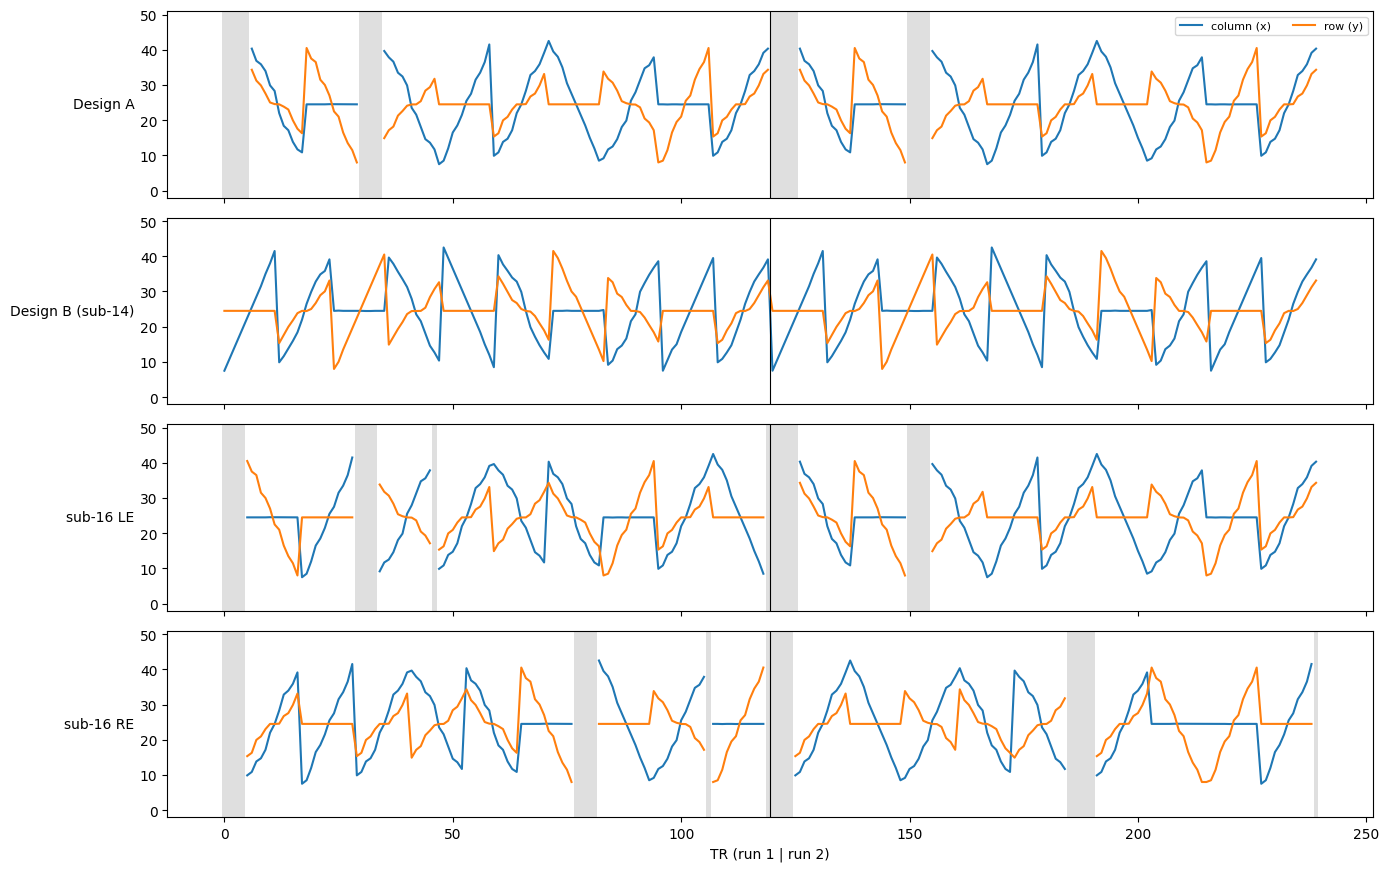

In [3]:
ys, xs = np.mgrid[0:vdm['Design A'].shape[0], 0:vdm['Design A'].shape[1]]
fig, axes = plt.subplots(len(designs), 1, figsize=(14, 2.2 * len(designs)), sharex=True)
for ax, name in zip(axes, designs):
    v = vdm[name][:, :, :n_tr]
    s = v.sum(axis=(0, 1))
    with np.errstate(invalid='ignore', divide='ignore'):
        cy = np.where(s > 0, (v * ys[..., None]).sum(axis=(0, 1)) / s, np.nan)
        cx = np.where(s > 0, (v * xs[..., None]).sum(axis=(0, 1)) / s, np.nan)
    ax.plot(cx, label='column (x)')
    ax.plot(cy, label='row (y)')
    ax.axvline(run_len - 0.5, color='k', lw=0.8)
    for t in np.where(s == 0)[0]:
        ax.axvspan(t - 0.5, t + 0.5, color='grey', alpha=0.25, lw=0)
    ax.set_ylabel(name, rotation=0, ha='right', va='center')
    ax.set_ylim(-2, v.shape[0] + 1)
axes[0].legend(loc='upper right', ncol=2, fontsize=8)
axes[-1].set_xlabel('TR (run 1 | run 2)')
plt.tight_layout()
fig.savefig('{}/vdm_bars_centroid.pdf'.format(out_dir))
plt.show()

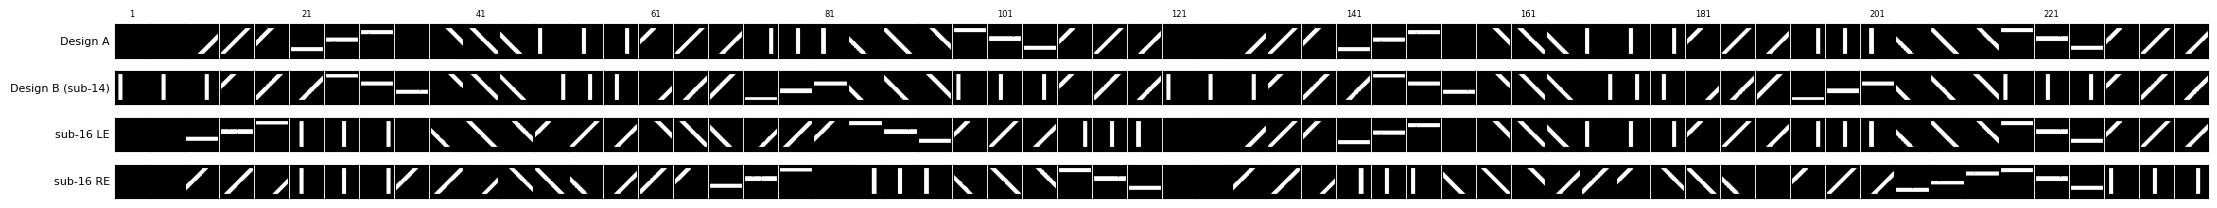

In [4]:
step = 4
ts = np.arange(0, n_tr, step)
fig, axes = plt.subplots(len(designs), len(ts), figsize=(len(ts) * 0.45, len(designs) * 0.6))
for r, name in enumerate(designs):
    for c, t in enumerate(ts):
        ax = axes[r, c]
        ax.imshow(vdm[name][:, :, t], cmap='gray', vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0 and c % 5 == 0:
            ax.set_title(str(t + 1), fontsize=6)
    axes[r, 0].set_ylabel(name, rotation=0, ha='right', va='center', fontsize=8)
plt.subplots_adjust(wspace=0.05, hspace=0.05)
fig.savefig('{}/vdm_bars_montage.pdf'.format(out_dir), bbox_inches='tight')
plt.show()